# Lesson 0: Python and Colab basics

<p class="lead">
Just enough Python to follow every lesson in this course. No installation, no previous coding: you run everything in your web browser.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/00_python_and_colab_basics.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## What you will be able to do

By the end of this lesson you will be able to:

1. Open a notebook in Google Colab and run its cells.
2. Store values in variables and do simple calculations.
3. Create a small table (a pandas **DataFrame**) and look at it.
4. Select columns, filter rows, add up numbers and count things.
5. Draw a simple bar chart.

> **How the course uses code**
>
> Every lesson gives you **working code** with explanations. You **read** it, **run** it, then **change** a few lines in the exercises. You will not be asked to write programs from scratch.

---

## Part 1: Google Colab in two minutes

Google Colab is a free website for running Python notebooks. You need a Google account.

1. Go to [colab.research.google.com](https://colab.research.google.com/).
2. Choose **File → Upload notebook** and select the lesson's `.ipynb` file.
3. A notebook is made of **cells**. Text cells explain; code cells run.
4. Click inside a code cell and press **Shift + Enter** to run it. The result appears underneath.
5. Run cells **from top to bottom**. Later cells use results from earlier ones.

> **If something goes wrong**
>
> Choose **Runtime → Restart session and run all**. This starts again from the top and fixes most problems.

---

## Part 2: Values and variables

A **variable** is a name for a value. The `=` sign stores the value under that name.

In [1]:
price = 120
quantity = 3
total = price * quantity
total

360

The last line of a cell is shown as the output. You can also use `print` to show several things.

In [2]:
discount = 0.10
print("Total before discount:", total)
print("Total after discount:", total * (1 - discount))

Total before discount: 360
Total after discount: 324.0


Text goes inside quotes, and a **list** holds several values in square brackets.

In [3]:
segment = "Consumer"
monthly_sales = [120, 95, 140, 180]
print(segment, "sales in four months:", monthly_sales)
print("Total:", sum(monthly_sales))
print("Number of months:", len(monthly_sales))

Consumer sales in four months: [120, 95, 140, 180]
Total: 535
Number of months: 4


> **Your turn:** change the code in the next cell and run it again.

In [4]:
# Change the numbers in the list, then run the cell again.
monthly_sales = [120, 95, 140, 180]
print("Average monthly sales:", sum(monthly_sales) / len(monthly_sales))

Average monthly sales: 133.75


---

## Part 3: Tables with pandas

**pandas** is the Python library analysts use for tables. A table in pandas is called a **DataFrame**. We first `import` the library, then build a small made-up table of five orders.

In [5]:
import pandas as pd

orders = pd.DataFrame({
    "order_id": ["A1", "A2", "A3", "A4", "A5"],
    "region": ["North", "South", "North", "East", "South"],
    "sales": [250.0, 120.0, 90.0, 310.0, 180.0],
    "items": [3, 1, 2, 4, 2],
})
orders

,order_id,region,sales,items
0,A1,North,250.0,3
1,A2,South,120.0,1
2,A3,North,90.0,2
3,A4,East,310.0,4
4,A5,South,180.0,2


Each **row** is one order. Each **column** has a name. Useful first checks:

In [6]:
print("Rows and columns:", orders.shape)
print(orders.dtypes)

Rows and columns: (5, 4)
order_id     object
region       object
sales       float64
items         int64
dtype: object


`dtypes` shows each column's type: `object` means text, `int64` whole numbers, `float64` decimals.

---

## Part 4: Select, filter, add up, count

**Select one column** with its name in square brackets:

In [7]:
orders["sales"]

0    250.0
1    120.0
2     90.0
3    310.0
4    180.0
Name: sales, dtype: float64

**Add up** or **average** a column:

In [8]:
print("Total sales:", orders["sales"].sum())
print("Average sales per order:", orders["sales"].mean())

Total sales: 950.0
Average sales per order: 190.0


**Filter rows** with a condition. This keeps only orders from the North region:

In [9]:
north = orders[orders["region"] == "North"]
north

,order_id,region,sales,items
0,A1,North,250.0,3
2,A3,North,90.0,2


**Count** how many rows, and how many **different** values a column has:

In [10]:
print("Number of orders:", len(orders))
print("Number of different regions:", orders["region"].nunique())

Number of orders: 5
Number of different regions: 3


> **Your turn:** change the code in the next cell and run it again.

In [11]:
# Change "North" to "South" and run again. How many South orders are there,
# and what are their total sales?
selected = orders[orders["region"] == "North"]
print(len(selected), "orders, total sales", selected["sales"].sum())

2 orders, total sales 340.0


---

## Part 5: Group and summarise

`groupby` splits the table into groups and summarises each one. Here: total sales for each region.

In [12]:
sales_by_region = orders.groupby("region")["sales"].sum()
sales_by_region

region
East     310.0
North    340.0
South    300.0
Name: sales, dtype: float64

---

## Part 6: Your first chart

pandas can draw a chart directly from a summary. `kind="barh"` makes horizontal bars.

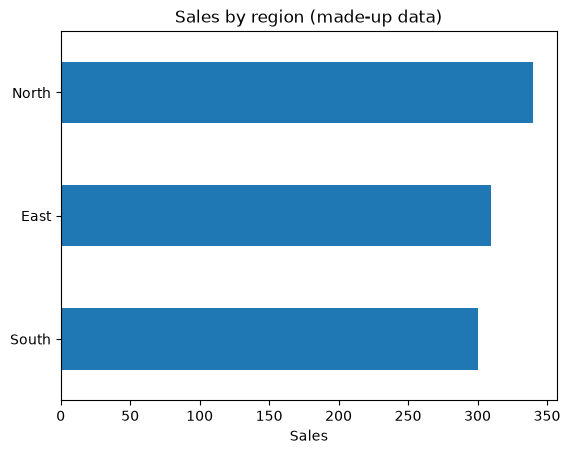

In [13]:
import matplotlib.pyplot as plt

sales_by_region.sort_values().plot(kind="barh", title="Sales by region (made-up data)")
plt.xlabel("Sales")
plt.ylabel("")
plt.show()

> **Your turn:** change the code in the next cell and run it again.

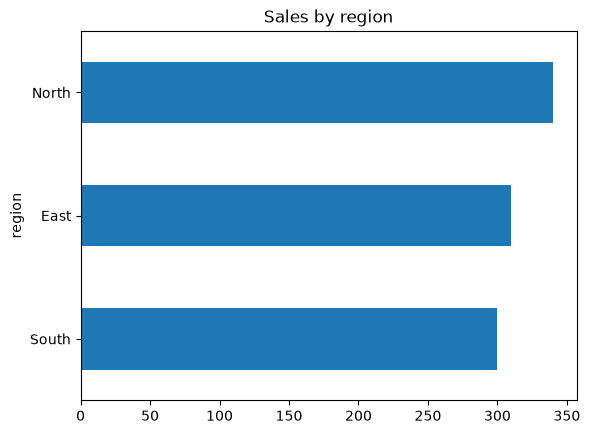

In [14]:
# Change "sales" to "items" to chart the number of items per region instead.
# Then change the title to match.
orders.groupby("region")["sales"].sum().sort_values().plot(kind="barh", title="Sales by region")
plt.show()

---

## Quick reference

| You want to… | Code |
|---|---|
| See the first rows | `df.head()` |
| Size of the table | `df.shape` |
| Column types | `df.dtypes` |
| One column | `df["sales"]` |
| Filter rows | `df[df["region"] == "North"]` |
| Total / average | `df["sales"].sum()` / `df["sales"].mean()` |
| Count rows / different values | `len(df)` / `df["region"].nunique()` |
| Total per group | `df.groupby("region")["sales"].sum()` |
| Bar chart | `series.plot(kind="barh")` |

---

## Exit ticket

1. What does pressing **Shift + Enter** do?
2. What is the difference between `len(df)` and `df["region"].nunique()`?
3. Which code would give total sales for each region?

Next: [Lesson 1](01_decision_to_evidence.md), where you load a real retail dataset.